# 07 — Probability and transition hypotheses

This notebook explains the transition layer rather than presenting another competing possession model. It separates:

`observations → scenario evidence → transition/no-switch hypotheses → interval resolver → optional Viterbi smoothing`

The immediate problem is not just defining more scenario labels. It is deciding when observations are trustworthy enough to change ownership, while preserving a no-switch or contested alternative during flight, poor touch, deflection, crowding, and occlusion. Optional source-aware path evidence contributes provenance and uncertainty only; it is never treated as a possession label.

The transition layer is case-specific:

| Boundary | Hypothesis asked | Confirmation needed |
|---|---|---|
| H → A / A → H in live play | Did an opponent touch become controlled possession? | Contact/deceleration or direction change + team arrival + post-touch persistence; otherwise `NO_SWITCH`/`CONTESTED` |
| D → H / D → A | Has a restart actually become live? | Restart-compatible movement plus stable team control; repositioning alone remains `RESTART_PHASE_UNRESOLVED` |
| H/A → D | Did play stop? | Out-of-play geometry or restart/dead-ball evidence; no-pressure movement alone is only a candidate |
| H/A → D → H/A with missing ball | What happened inside the interval? | Pre-gap anchor + path provenance/uncertainty + arrival/control after reappearance |

A long-ball departure therefore carries the launching team's continuity anchor until the flight/landing boundary. It does not award the landing: an opposing controlled reception must still survive the interval resolver.

When an alternate observation is available, it can affect this continuity hypothesis only inside an eligible tactical gap; on visible tactical frames it remains an auditable geometry signal rather than an ownership override. The path-fusion audit records agreement/disagreement and passes selected geometry to player-arrival evidence. If paths disagree, the transition layer becomes more uncertain rather than switching ownership.

## What kind of model is this?

The current pipeline is **not supervised learning**: the public ground truth is never used to fit weights, thresholds, transition costs, or labels. It is also not really unsupervised learning, because it does not discover parameters or latent states from an unlabeled dataset. The most accurate description is **knowledge-driven, rule-based probabilistic inference**.

The rules encode domain assumptions about control, flight, pressure, restarts, anchors, and missing-ball causes. Weighted scores and softmax turn those assumptions into comparable evidence values; interval logic and Viterbi perform model-based sequence inference. The word probability describes normalized uncertainty, not learned empirical frequency.

The taxonomy would change only when we fit parameters: calibration against reviewed labels would be supervised calibration; EM or another latent-state fitting procedure without labels would be unsupervised/semi-supervised learning; learned episode-duration distributions would make an HSMM data-driven rather than hand-specified. Until then, ground truth belongs to evaluation and error analysis only.

The physical observations behind this layer are shown in [03_scenario_engineering.ipynb](03_scenario_engineering.ipynb) and the restart/transition boundary study in [04_deadball_setpieces.ipynb](04_deadball_setpieces.ipynb). This notebook turns those observations into competing transition hypotheses rather than adding more final labels.

## Calibration and learning experiments

The promoted system is deliberately not fitted to the public labels. Temperature scaling, transition priors, EM-HMM/HSMM duration learning, and empirical leave-one-channel-out stability are useful follow-up experiments, but they require a declared calibration/holdout protocol. Their comparisons are kept in [appendix/09_experimental_results.ipynb](appendix/09_experimental_results.ipynb) rather than mixed into this organiser-facing resolver.

The nonparametric stability idea is especially useful for robustness: perturb one evidence family inside an interval and measure how often the same hypothesis wins. That measures decision stability, not truth probability.

## New signal under test: contact → arrival coherence

A direction change or ball deceleration can be a deflection, not a turnover. `contact_arrival_coherence` therefore combines a plausible contact event with bounded future arrival, reception, or post-control support. It is soft evidence only: it cannot create an anchor or replace `NO_SWITCH`/`CONTESTED`. Its public comparison is kept in the optional audit notebook.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / 'possession_lab').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
REPORTS = ROOT / 'evaluation' / 'reports'
RESULTS = ROOT / 'evaluation' / 'results'
print('project root:', ROOT)
print('reports:', REPORTS)
print('runner:', ROOT / 'possession_lab' / 'run_interpolated_flight_experiment.py')

project root: /Users/luke/Desktop/barca-hack-repo-staging
reports: /Users/luke/Desktop/barca-hack-repo-staging/evaluation/reports
runner: /Users/luke/Desktop/barca-hack-repo-staging/possession_lab/run_interpolated_flight_experiment.py


## What a transition scenario asks us to observe

The scenario is a question about the evidence, not the final label. For example, `LONG_BALL` asks whether a flight ended in same-team control, an opposing control, or an unresolved contest. The transition layer therefore records the following observations before it selects an owner:

| Observation | What it can support | What it cannot prove alone |
|---|---|---|
| Ball acceleration, speed, direction and sharp change in direction | kick, reception, deflection, or continued flight | that the nearest player owns the ball |
| Distance margin, closing speed and predicted arrival time | which team could reach/control the ball first | that a player actually touched it |
| Local density, pressure and converging trajectories | contested, deflection, or dead-ball explanation | a definite turnover |
| Player/ball visibility and missing-ball cause | occlusion or geometric bridge uncertainty | possession during the gap |
| Post-touch ball persistence and controlled deceleration | stable reception/control anchor | the identity of a brief touch in isolation |
| Restart geometry and coordinated player movement | goal kick, corner, throw-in, free kick, kick-off, or dead ball | that a restart is taken merely because players are repositioning |

These observations create competing hypotheses: `SWITCH_TO_H`, `SWITCH_TO_A`, `NO_SWITCH`, and `CONTESTED/OCCLUDED`. The probability vector expresses their relative evidence; the interval resolver decides when the evidence is sufficient; Viterbi may then smooth the accepted path.

## 1. Observation probabilities

For every frame, the feature layer combines control, reception, flight, dead-ball, crowd, contest, missing-ball, distance-margin, and anchor evidence into `[P(H), P(A), P(D), P(X)]`. `X` means uncertain/abstain.

These values are currently a normalized rule-evidence vector produced with a softmax. They are **not calibrated probabilities**: `0.8` does not yet mean 80% empirical correctness. Their role is to keep evidence channels visible and give later decoders bounded emission-like inputs.

### The actual mathematics used

The current implementation is a transparent weighted-score model, not a learned generative HMM. Each evidence channel is first clipped or normalized to a comparable range. The possession-state logits are weighted sums, for example:

`z_H = 1.20 control_H + 0.85 reception_H + 0.35 post_H + 0.25 direction_H + 0.45 margin_H + 3.50 anchor_H`

with an analogous `z_A`; dead-ball and uncertainty receive their own logits. We convert logits to an evidence vector with the softmax:

`p_k = exp(z_k / T) / sum_j exp(z_j / T)`

where `k` is `H`, `A`, `D`, or `X`. The temperature is a numerical/evidence-sharpness parameter; because the weights were not fitted on reviewed labels, these are not calibrated probabilities.

For a possible switch, the trust score is another weighted sum. It combines opposite-anchor agreement, reception, post-contact persistence, proximity, closing/arrival geometry, contact physics, and flight support, then subtracts contest and occlusion penalties. The interval hypotheses are then normalized with another softmax over:

`[2 mean(trust_H), 2 mean(trust_A), no_switch_logit, contested_logit]`.

The resolver first finds an active interval from transition evidence, merges gaps of at most two frames, and aggregates evidence over that interval. It marks the interval `OCCLUDED` when at least half its frames are missing, `CONTESTED` when contest evidence is at least `0.6` or the H/A trust margin is below `0.08`, and otherwise creates a `SWITCH_CANDIDATE`. These are hypothesis-generation rules; deterministic anchors and the later interval resolver still control ownership.

In [2]:
probability_path = REPORTS / 'observation_probability_audit.csv'
columns = [
    'frame', 'scenario_context', 'scenario_state',
    'observation_probability_H', 'observation_probability_A',
    'observation_probability_D', 'observation_probability_X',
    'observation_probability_entropy', 'observation_probability_margin',
    'observation_probability_calibrated', 'observation_probability_model',
    'missing_ball_cause', 'scenario_crowd_score',
    'transition_hypothesis_state',
]
available = pd.read_csv(probability_path, nrows=0).columns
usecols = [column for column in columns if column in available]
probability = pd.read_csv(probability_path, usecols=usecols)
state_cols = [column for column in [
    'observation_probability_H', 'observation_probability_A',
    'observation_probability_D', 'observation_probability_X'
] if column in probability]
probability['probability_sum'] = probability[state_cols].sum(axis=1)
print('rows:', len(probability))
print('maximum normalization error:', float((probability['probability_sum'] - 1.0).abs().max()))
print('calibrated flag:', probability.get('observation_probability_calibrated', pd.Series(dtype=object)).unique())
probability[state_cols + ['observation_probability_entropy', 'observation_probability_margin']].describe()

rows: 199319
maximum normalization error: 4.440892098500626e-16
calibrated flag: [False]


,observation_probability_H,observation_probability_A,observation_probability_D,observation_probability_X,observation_probability_entropy,observation_probability_margin
count,199319.000000,199319.000000,199319.000000,199319.000000,199319.000000,199319.000000
mean,0.244629,0.196304,0.327523,0.231544,0.659922,0.476139
std,0.277544,0.241900,0.295385,0.171780,0.222770,0.217778
min,0.002388,0.001938,0.002047,0.002047,0.033082,0.000007
25%,0.020756,0.020756,0.109860,0.115134,0.499804,0.349835
50%,0.125851,0.109860,0.163470,0.191704,0.688760,0.495305
75%,0.409268,0.215413,0.708123,0.268411,0.845631,0.575079
max,0.993580,0.992909,0.822905,0.725469,0.998348,0.991440


## 2. Transition hypotheses are interval-level

The transition layer asks two separate questions:

1. Is a transition-like event happening?
2. If so, which team should own the next state?

Each interval keeps explicit alternatives: `H`, `A`, `NO_SWITCH`, and `CONTESTED`/`OCCLUDED`. A kick, direction change, receiver path, control signal, opposite anchor, crowd, deflection risk, or Kalman path can open an interval, but cannot own the next state by itself. This is how we avoid overwriting possession because of one noisy frame between two reliable anchors.

In [3]:
ledger = pd.read_csv(REPORTS / 'transition_hypothesis_ledger.csv')
ledger_cols = [column for column in ['p_H', 'p_A', 'p_no_switch', 'p_contested'] if column in ledger]
if ledger_cols:
    ledger['hypothesis_probability_sum'] = ledger[ledger_cols].sum(axis=1)
print('transition intervals:', len(ledger))
print(ledger.get('state', pd.Series(dtype=object)).value_counts(dropna=False))
if ledger_cols:
    print('maximum interval normalization error:', float((ledger['hypothesis_probability_sum'] - 1.0).abs().max()))
ledger.head(10)

transition intervals: 1306
state
NO_SWITCH           1098
SWITCH_CANDIDATE     198
CONTESTED             10
Name: count, dtype: int64
maximum interval normalization error: 2.220446049250313e-16


,interval_id,start_frame,end_frame,duration_frames,state,hypothesis_team,candidate_team,activity_max,activity_mean,p_H,...,closing_rate_max_mps,ball_speed_max_mps,kalman_path_available,kalman_reliable,kalman_uncertainty_max_m,missing_ball_cause,evidence_reason,conflict_reason,decoder_action,hypothesis_probability_sum
0,0,4198,4198,1,NO_SWITCH,NaN,A,0.226568,0.226568,0.121482,...,NaN,0.343908,False,False,0.139941,UNKNOWN,RECEPTION_GEOMETRY|DIRECTION_CHANGE,NONE,RETAIN_PRIOR_STATE,1.0
1,1,4203,4206,4,NO_SWITCH,NaN,H,0.228691,0.123683,0.135371,...,NaN,0.526587,False,False,0.252902,UNKNOWN,RECEPTION_GEOMETRY|DIRECTION_CHANGE,NONE,RETAIN_PRIOR_STATE,1.0
2,2,11359,11359,1,NO_SWITCH,NaN,A,0.055526,0.055526,0.102573,...,-0.539366,1.472524,False,False,0.128559,UNKNOWN,RECEPTION_GEOMETRY,NONE,RETAIN_PRIOR_STATE,1.0
3,3,11393,11396,4,NO_SWITCH,NaN,A,0.176666,0.120059,0.115989,...,2.146664,0.476602,False,False,0.128559,UNKNOWN,RECEPTION_GEOMETRY|DIRECTION_CHANGE,NONE,RETAIN_PRIOR_STATE,1.0
4,4,11608,11610,3,NO_SWITCH,NaN,H,0.087292,0.080835,0.066062,...,-0.367579,0.515097,False,False,0.128559,UNKNOWN,RECEPTION_GEOMETRY|CONTEST,COMPETING_PLAYERS|SAME_ANCHOR_CONTINUITY,RETAIN_PRIOR_STATE,1.0
5,5,11715,11716,2,NO_SWITCH,NaN,A,0.248294,0.198871,0.066762,...,1.779116,0.826542,False,False,0.128559,UNKNOWN,RECEPTION_GEOMETRY|DIRECTION_CHANGE,NONE,RETAIN_PRIOR_STATE,1.0
6,6,11799,11801,3,NO_SWITCH,NaN,H,0.176113,0.147157,0.070677,...,6.576238,1.027654,False,False,0.128559,UNKNOWN,RECEPTION_GEOMETRY|CONTEST,COMPETING_PLAYERS,RETAIN_PRIOR_STATE,1.0
7,7,11943,11944,2,SWITCH_CANDIDATE,H,H,0.252395,0.194319,0.167640,...,5.640314,0.487505,False,False,0.128559,UNKNOWN,RECEPTION_GEOMETRY|DIRECTION_CHANGE,NONE,RETAIN_PRIOR_STATE,1.0
8,8,11961,11963,3,NO_SWITCH,NaN,H,0.108596,0.101550,0.127192,...,3.242829,0.374861,False,False,0.128559,UNKNOWN,RECEPTION_GEOMETRY,SAME_ANCHOR_CONTINUITY,RETAIN_PRIOR_STATE,1.0
9,9,11973,11973,1,NO_SWITCH,NaN,H,0.237048,0.237048,0.151639,...,3.655102,0.105341,False,False,0.128559,UNKNOWN,RECEPTION_GEOMETRY|DIRECTION_CHANGE,SAME_ANCHOR_CONTINUITY,RETAIN_PRIOR_STATE,1.0


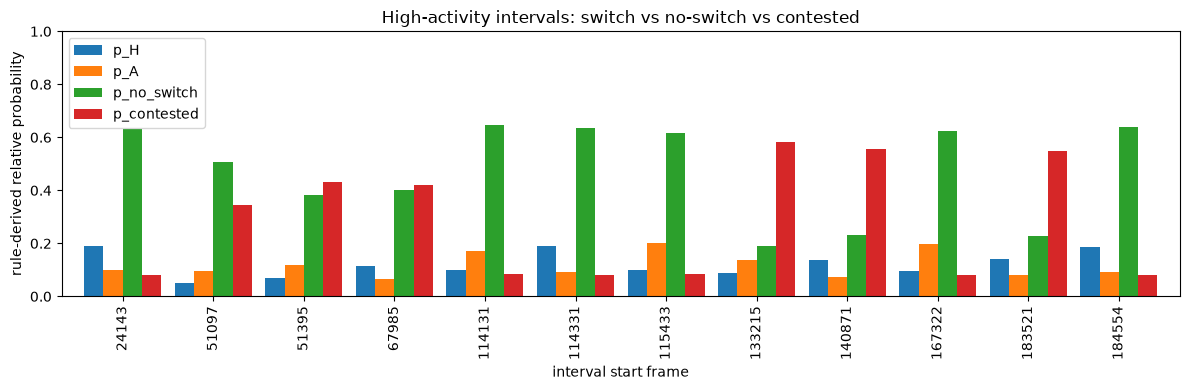

In [4]:
if not ledger.empty and ledger_cols:
    view = ledger.sort_values(['activity_max', 'start_frame'], ascending=[False, True]).head(12).sort_values('start_frame')
    ax = view.set_index('start_frame')[ledger_cols].plot.bar(
        figsize=(12, 4), ylim=(0, 1), width=0.85,
        title='High-activity intervals: switch vs no-switch vs contested'
    )
    ax.set_xlabel('interval start frame')
    ax.set_ylabel('rule-derived relative probability')
    plt.tight_layout()
    plt.show()

## 2a. The signal we are actually using: continuity versus switch

### Problem

A nearest-player change, a brief contact, or a ball-direction change can look like a turnover even when the ball is still travelling, being contested, or being miscontrolled. Overwriting the state on that frame creates short false H/A spells. The useful question is therefore not simply `who is closest?`, but whether there is enough independent evidence to replace the previous owner.

### Idea

Treat `NO_SWITCH` as an explicit continuity hypothesis. It means: *a transition-like observation may be occurring, but the evidence currently supports keeping the prior live team until a new controlled state is confirmed*. It is not a third possession label, and it is not permission to copy the public label across a gap.

### Construct

The signal is assembled from observations already produced by the pipeline:

- `transition_activity_score`: is there a transition-like event worth investigating?
- `transition_hypothesis_state`: is the interval `NO_SWITCH`, `CONTESTED`, `OCCLUDED`, or `SWITCH_CANDIDATE`?
- `transition_hypothesis_p_no_switch`: normalized relative support for continuity versus H/A switch and contest alternatives.
- `transition_no_switch_cause_support`: flight/control evidence or a kick that supports the current team continuing the play.
- `selected_anchor_team` and `selected_anchor_confidence`: whether a new deterministic anchor independently confirms the proposed team.
- `controlled_reception_signal` and its score: whether the proposed team has actually controlled the ball after the ambiguous interval.
- scenario and visibility context: `BALL_IN_FLIGHT`, `CONTESTED`, `RECEPTION_CANDIDATE`, `MISCONTROL_CANDIDATE`, `PRESSURED_CONTROL`, `CONTROLLED`, `UNKNOWN`, or `OCCLUDED`.

For a proposed H/A run `I`, the resolver computes the observable support fraction

`S_NS(I) = mean_t 1[live_t] 1[state_t = NO_SWITCH] 1[p_NS(t) >= tau_NS]`.

It retains the preceding team only when `S_NS(I) >= tau_I`, the preceding team has enough prior context, and there is no strong new anchor or controlled-reception signal for the proposed team. Explicit `D`/`X` frames are preserved. The current implementation uses `tau_NS = 0.65` and `tau_I = 0.60` as engineering guards, not learned probabilities.

### What this signal can and cannot say

It can suppress a premature switch during flight, contest, occlusion, or a poor touch. It cannot prove that the prior team touched the ball, identify a hidden player, or replace a genuine opposing control anchor. That is why the signal is resolved over an interval and always competes with `SWITCH_TO_H`, `SWITCH_TO_A`, and `CONTESTED/OCCLUDED`.

This is a knowledge-driven, rule-based probabilistic inference signal. The softmax values are currently uncalibrated evidence weights; public ground truth is used below only for evaluation in other notebooks, never to construct this ledger.

intervals with continuity guard active: 407
interval action counts:


,intervals
decoder_action,
RETAIN_PRIOR_STATE,1274
ELIGIBLE_AFTER_ANCHOR_CHECK,22
HOLD_OR_ABSTAIN,10


mean evidence by hypothesis state:


,p_no_switch,no_switch_support_max,activity_max,duration_frames
state,,,,
CONTESTED,0.519,0.900,0.277,16.100
NO_SWITCH,0.613,0.338,0.157,5.332
SWITCH_CANDIDATE,0.514,0.687,0.280,12.879


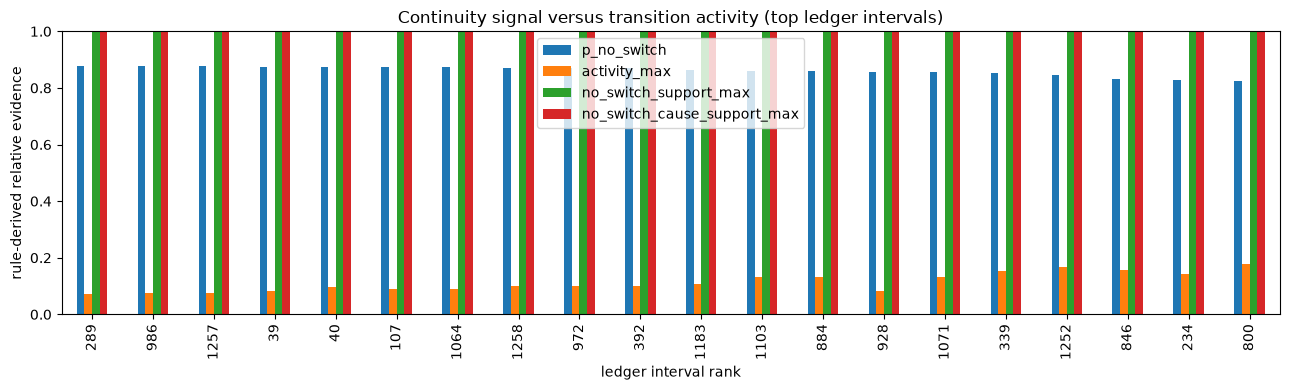

In [5]:
# Ground-truth-free audit: show what the continuity signal is seeing.
signal_columns = [
    'state', 'decoder_action', 'scenario_context', 'p_no_switch',
    'no_switch_support_max', 'no_switch_cause_support_max',
    'activity_max', 'duration_frames', 'missing_ball_cause'
]
signal_view = ledger[[column for column in signal_columns if column in ledger.columns]].copy()
if not signal_view.empty:
    signal_view['p_no_switch_ge_065'] = signal_view['p_no_switch'] >= 0.65
    signal_view['continuity_guard_active'] = (
        signal_view['state'].eq('NO_SWITCH') & signal_view['p_no_switch_ge_065']
    )
    print('intervals with continuity guard active:', int(signal_view['continuity_guard_active'].sum()))
    print('interval action counts:')
    display(signal_view['decoder_action'].value_counts(dropna=False).rename_axis('decoder_action').to_frame('intervals'))
    print('mean evidence by hypothesis state:')
    display(
        signal_view.groupby('state', dropna=False)[
            ['p_no_switch', 'no_switch_support_max', 'activity_max', 'duration_frames']
        ].mean().round(3)
    )

    strongest = signal_view.sort_values(
        ['continuity_guard_active', 'p_no_switch', 'activity_max'],
        ascending=[False, False, False]
    ).head(20)
    strongest[['p_no_switch', 'activity_max', 'no_switch_support_max', 'no_switch_cause_support_max']].plot.bar(
        figsize=(13, 4), ylim=(0, 1),
        title='Continuity signal versus transition activity (top ledger intervals)'
    )
    plt.ylabel('rule-derived relative evidence')
    plt.xlabel('ledger interval rank')
    plt.tight_layout()
    plt.show()

## 3. Resolver first; Viterbi and HSMM are later layers

The interval resolver is the first ownership decision layer. It requires bounded evidence such as opposing anchors, plausible reception/control, post-contact persistence, and compatible geometry. It can preserve the prior team or abstain. The current best ablation makes the explicit `NO_SWITCH` alternative operational: when a proposed H/A run is mostly supported by no-switch evidence and lacks a new control anchor, it retains the prior team through that interval.

Viterbi is an optional constrained path smoother after this layer. It may prefer a globally coherent path, but it must not invent evidence; hard anchors and explicit dead-ball constraints remain protected. Contested and occluded intervals make a switch more expensive.

HSMM is not the default yet because we do not have reliable duration distributions for live possession, dead-ball, flight, and contest episodes. Kalman is upstream geometry support only: it estimates a missing-ball path and uncertainty; it does not decide possession.

### The next signals: useful evidence, unsafe hard rewrites

The disagreement audit suggested two useful signal families: confirm a switch with post-contact ball change, team-level arrival, and persistence; and keep `D` until restart-compatible movement agrees with stable team control. These remain soft evidence because a poor touch or a deflection can look similar. Detailed rejected variants and scores are kept in [`appendix/5_MODELS_AND_RESULTS.md`](../possession_lab/appendix/5_MODELS_AND_RESULTS.md) and [`appendix/6_APPENDIX_RETIRED_EXPERIMENTS.md`](../possession_lab/appendix/6_APPENDIX_RETIRED_EXPERIMENTS.md).

In [6]:
candidate_paths = {
    'resolver candidate': RESULTS / 'diagnostic_visible_ball_no_switch_interval.csv',
    'restart phase interval candidate': RESULTS / 'diagnostic_no_switch_restart_phase_interval.csv',
    'transition-ledger Viterbi': RESULTS / 'baseline_transition_ledger_viterbi.csv',
    'probability-emission Viterbi': RESULTS / 'baseline_probability_transition_ledger_viterbi.csv',
    'duration-aware diagnostic': RESULTS / 'baseline_scenario_confidence_duration.csv',
}
for name, path in candidate_paths.items():
    print(f'{name}: {"available" if path.exists() else "not generated"} — {path.name}')
print('These are decoder variants for evaluation, not independent truth sources.')

resolver candidate: available — diagnostic_visible_ball_no_switch_interval.csv
restart phase interval candidate: available — diagnostic_no_switch_restart_phase_interval.csv
transition-ledger Viterbi: available — baseline_transition_ledger_viterbi.csv
probability-emission Viterbi: available — baseline_probability_transition_ledger_viterbi.csv
duration-aware diagnostic: available — baseline_scenario_confidence_duration.csv
These are decoder variants for evaluation, not independent truth sources.


## 3a. Restart observations as constraints, not labels

### Problem

The restart state machine and delayed handoff each make reasonable observations, but sequential label writers can disagree about the same interval. A restart tag, player repositioning, or a ball reappearance is evidence that a restart phase may be active; it is not by itself proof that H or A owns the next frame.

### Idea

Represent restart timing separately from possession. The shared resolver receives a phase and switch-permission constraint, then chooses between the existing H/A candidate, the prior owner, `D`, or `X`. This keeps the explicit no-switch/contested alternative and prevents restart context from inventing a live owner.

### Construct

`add_restart_phase_features` emits `OUTSIDE_RESTART`, `PRE_RESTART`, `ACTIVE_UNCONTROLLED`, and `CONTROL_CONFIRMED` from Smart Tagging/restart context, ball-activity evidence, and a sustained independent team anchor. `restart_phase_interval_resolver` then applies two constraints: before control is confirmed, reject a new H/A handoff that contradicts the preceding live team; after control is confirmed, release an existing `D` only to the sustained anchor team. Neither function reads ground truth.

This is the intended composition: `restart observations -> restart phase/evidence -> transition constraints -> shared interval resolver -> final H/A/D/X label`. The implementation is in `possession_lab/decoder_experiments.py`; the full-match candidate is written by `08_run_pipeline.ipynb`.

### Evaluation

The restart-phase composition is retained as a diagnostic because it separates restart evidence from ownership. It is not promoted as a second label writer; the active candidate remains the shared `NO_SWITCH` interval resolver. Detailed ablations and public scores are in the appendix.

## 4. Further experiments

Calibration, empirical stability, and alternative sequence decoders are deliberately separated from the promoted resolver. They must use declared contiguous calibration/holdout windows and preserve anchors and dead-ball constraints. See [appendix/09_experimental_results.ipynb](appendix/09_experimental_results.ipynb) for the audit; ground truth remains evaluation-only during inference.

## 5. Explicit channel-composition experiment

The transition vector is tested as an explicit composition of anchor agreement, ball motion/contact, player arrival, and restart/continuity context. `NO_SWITCH` and `CONTESTED` remain competing interval hypotheses. The feature layer keeps one pre-anchor observation scenario for audit and one final scenario context after anchor selection; this is staged evidence, not a second possession model.

Predeclared channel-dropout and bounded reweighting results are reported in [appendix/09_experimental_results.ipynb](appendix/09_experimental_results.ipynb). They are sensitivity measurements, not correctness labels, and they do not replace the promoted resolver.

## 6. Contact and team-arrival signal experiment

### Problem

The transition-channel audit says ball-motion/contact and player-arrival evidence matter most. The weakness is not simply a missing weight: one nearest player can be misleading, and a missing-ball interval can be propagated from one local clue.

### Idea and construction

The feature layer now keeps the fastest arrival ETA and adds a soft consensus from the best three reachable players. It also compares visible motion immediately before and after a missing-ball run, recording two-sided direction agreement and relative speed as trajectory-continuity evidence. These functions feed transition hypotheses and the `NO_SWITCH`/`CONTESTED` alternatives; they do not assign H/A and do not train on public labels.

### Evaluation

The feature is retained as soft evidence, but a hard early handoff gate is not promoted: weak observations can confirm a handoff later, so the gate must not overrule the interval resolver. The rejected guard is recorded in the appendix.

## 7. Why fitted sequence decoders are not in the promoted resolver

A classifier or Viterbi path fitted from event-derived or silver labels is a separate supervised/weakly supervised decoder. It may be useful when its training distribution matches the target data, but it can commit to switches or fragment spells without the anchor semantics used here.

Those comparisons remain appendix-only. The promoted runner uses the label-free, knowledge-driven evidence vector and bounded resolver described above.

## What the transition score means

**Problem → idea → construction.** We cannot observe possession truth directly; we observe tracking, ball motion, player arrival, restart context, and optional collaborator clues. The transition layer therefore constructs competing interval hypotheses rather than declaring a switch from one nearest-player frame.

For a candidate interval I, the system aggregates bounded evidence channels: anchor agreement + ball motion/contact + player arrival + restart context + bounded auxiliary support, and normalises the resulting non-negative weights over H switch, A switch, NO_SWITCH, and CONTESTED.

This is an evidence vector or posterior-like score, not a calibrated probability. A softmax normalisation makes the values comparable and sum to one; it does not make them frequencies of truth. Calibration would require a declared reviewed-label training split and a held-out match. Public labels are used only by the evaluation notebooks after prediction.

The resolver then applies football constraints: protected anchors and D/X remain protected; a nearest-player change alone cannot switch ownership; a missing-ball bridge can preserve the prior team or remain contested; and a switch needs contact/motion and later team-level control support. Viterbi can be used later as constrained path decoding over these emissions. HSMM remains diagnostic until duration distributions are learned from trusted reviewed matches. Kalman estimates hidden ball geometry and uncertainty; it does not decide possession.